# RouteOpt — Experiment 002: 2-opt Robustness Across 30 Random Seeds

**Objective:** determine whether 2-opt continues to improve on Nearest Neighbor as customer locations change.

This experiment expands on the previous one by using 30 random seeds for each problem size. Brute Force runs only for up to 8 customers, where its exact solutions provide a reference. OR-Tools will be studied in a later experiment.

## Research Question and Hypothesis

**Research question:** How much does 2-opt improve Nearest Neighbor routes across different random instances, and how does its computational cost change as the number of customers increases?

**Hypothesis:** 2-opt will reduce route distance in a meaningful proportion of instances, at the cost of additional computation time. Brute Force will become expensive quickly and will therefore be limited to small problems.

## Experimental Design

- Customer counts: 5, 8, 12, and 20.
- Seeds: 2024–2053 (30 instances per size; 120 total).
- Synthetic coordinates drawn uniformly from a 100 × 100 square; depot at (50, 50).
- Algorithms: Nearest Neighbor, 2-opt, and Brute Force for up to 8 customers.
- Timing: median of 3 runs for each algorithm.
- Statistics: mean and standard deviation of route distances, percentage improvement, and share of instances improved.

The seeds make the instances reproducible; execution times may still vary between computers.

## Step 1 — Locate the project and import the benchmark

This cell searches for the directory containing `src/benchmark.py`, so it works whether Jupyter was opened from the project root or from `notebooks/`.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents) if (path / 'src' / 'benchmark.py').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find src/benchmark.py from the current directory')

sys.path.insert(0, str(PROJECT_ROOT / 'src'))
print(f'Project root: {PROJECT_ROOT}')

Project root: /Users/marcoshoejer/Desktop/routeopt


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from benchmark import run_benchmark, environment_metadata

CUSTOMER_SIZES = (5, 8, 12, 20)
SEEDS = tuple(range(2024, 2054))
REPETITIONS = 3

print(environment_metadata())

{'python': '3.11.8 (v3.11.8:db85d51d3e, Feb  6 2024, 18:02:37) [Clang 13.0.0 (clang-1300.0.29.30)]', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'numpy': '1.26.4', 'pandas': '2.2.3', 'matplotlib': '3.9.3'}


## Step 2 — Run all 120 instances

Each combination of problem size and seed generates one instance. Runtime is measured as the median of three runs to reduce the effect of one-off variations. The 12- and 20-customer instances are not compared with an exact optimum: running Brute Force on them would be too expensive.

In [3]:
results = run_benchmark(
    customer_sizes=CUSTOMER_SIZES,
    seeds=SEEDS,
    repetitions=REPETITIONS,
)

results['two_opt_improvement_pct'] = (
    (results['nearest_neighbor_distance'] - results['two_opt_distance'])
    / results['nearest_neighbor_distance'] * 100
)
results['two_opt_improved'] = (
    results['two_opt_distance']
    < results['nearest_neighbor_distance'] - 1e-10
)

print(f"Instances: {len(results)}")
display(results.head())

Instances: 120


,customers,seed,nearest_neighbor_distance,two_opt_distance,exact_distance,nearest_neighbor_time_s,two_opt_time_s,brute_force_time_s,nearest_neighbor_gap_pct,two_opt_gap_pct,nearest_neighbor_route,two_opt_route,two_opt_improvement_pct,two_opt_improved
0,5,2024,315.787997,255.508764,255.508764,0.000040,0.000308,0.001816,23.591846,0.0,"[0, 1, 5, 4, 2, 3, 0]","[0, 3, 1, 5, 4, 2, 0]",19.088513,True
1,5,2025,266.354868,240.668715,240.668715,0.000034,0.000388,0.001743,10.672826,0.0,"[0, 5, 1, 3, 2, 4, 0]","[0, 5, 3, 1, 2, 4, 0]",9.643583,True
2,5,2026,201.818799,194.780931,194.780931,0.000047,0.000654,0.002050,3.613222,0.0,"[0, 2, 5, 4, 3, 1, 0]","[0, 3, 1, 2, 5, 4, 0]",3.487221,True
3,5,2027,180.901988,180.901988,180.901988,0.000053,0.000190,0.001133,0.000000,0.0,"[0, 3, 4, 2, 1, 5, 0]","[0, 3, 4, 2, 1, 5, 0]",0.000000,False
4,5,2028,275.566185,226.482751,226.482751,0.000024,0.000188,0.001020,21.672041,0.0,"[0, 1, 4, 3, 5, 2, 0]","[0, 5, 3, 4, 2, 1, 0]",17.811849,True


## Step 3 — Summarize solution quality, variability, and runtime

- **Mean ± standard deviation of distance:** the average and spread across instances; this is not a confidence interval.
- **Mean/median improvement:** percentage reduction in distance from Nearest Neighbor to 2-opt for each instance.
- **Instances improved:** percentage of instances where 2-opt produced a strictly shorter route.
- **Exact optimality gap:** only for 5 and 8 customers, where Brute Force computes the optimum. A gap of 0% means the route matches that optimum.

The gaps for 12 and 20 customers are left blank. Comparing one heuristic with another does not establish a gap relative to the optimum.

In [4]:
summary = (
    results.groupby('customers', as_index=False)
    .agg(
        instances=('seed', 'count'),
        nn_distance_mean=('nearest_neighbor_distance', 'mean'),
        nn_distance_std=('nearest_neighbor_distance', 'std'),
        two_opt_distance_mean=('two_opt_distance', 'mean'),
        two_opt_distance_std=('two_opt_distance', 'std'),
        exact_distance_mean=('exact_distance', 'mean'),
        improvement_mean_pct=('two_opt_improvement_pct', 'mean'),
        improvement_median_pct=('two_opt_improvement_pct', 'median'),
        improved_instances_pct=('two_opt_improved', lambda x: 100 * x.mean()),
        nn_time_median_s=('nearest_neighbor_time_s', 'median'),
        two_opt_time_median_s=('two_opt_time_s', 'median'),
        brute_force_time_median_s=('brute_force_time_s', 'median'),
        nn_gap_mean_pct=('nearest_neighbor_gap_pct', 'mean'),
        two_opt_gap_mean_pct=('two_opt_gap_pct', 'mean'),
    )
)

display(summary.round(4))

,customers,instances,nn_distance_mean,nn_distance_std,two_opt_distance_mean,two_opt_distance_std,exact_distance_mean,improvement_mean_pct,improvement_median_pct,improved_instances_pct,nn_time_median_s,two_opt_time_median_s,brute_force_time_median_s,nn_gap_mean_pct,two_opt_gap_mean_pct
0,5,30,235.6450,40.7499,223.6420,39.4167,223.0464,5.0047,2.8743,70.0,0.0000,0.0002,0.0010,5.8915,0.235
1,8,30,300.3499,38.9744,275.8471,33.7052,274.3821,7.7840,7.1865,80.0,0.0001,0.0009,0.5132,9.5759,0.489
2,12,30,361.1304,50.7892,325.6045,36.0746,NaN,9.2716,9.5651,90.0,0.0001,0.0036,NaN,NaN,NaN
3,20,30,446.6585,50.3407,399.9726,35.1963,NaN,10.0407,9.3320,100.0,0.0003,0.0166,NaN,NaN,NaN


## Results Observed in This Run

The reference run produced the values below (distances in Euclidean units; times in seconds). Runtime values may change when rerun on another computer, but the instances are fixed by the seeds.

| Customers | Instances | NN mean distance ± SD | 2-opt mean distance ± SD | Mean improvement | Median improvement | Instances improved | Brute Force median |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 5 | 30 | 235.645 ± 40.750 | 223.642 ± 39.417 | 5.005% | 2.874% | 70% | 0.0010 s |
| 8 | 30 | 300.350 ± 38.974 | 275.847 ± 33.705 | 7.784% | 7.187% | 80% | 0.5100 s |
| 12 | 30 | 361.130 ± 50.789 | 325.605 ± 36.075 | 9.272% | 9.565% | 90% | No calculado |
| 20 | 30 | 446.659 ± 50.341 | 399.973 ± 35.196 | 10.041% | 9.332% | 100% | No calculado |

On average, 2-opt nearly matched the optimum on small problems, but not every time: the mean gap was approximately 0.235% with 5 customers and 0.489% with 8. This illustrates that 2-opt is a local search method, not a guarantee of global optimality.

The observed Brute Force median increased from approximately 0.0010 s with 5 customers to 0.5100 s with 8. This highlights its growth in computational cost; these times should not be extrapolated linearly.

## Step 4 — Visualize averages and variability

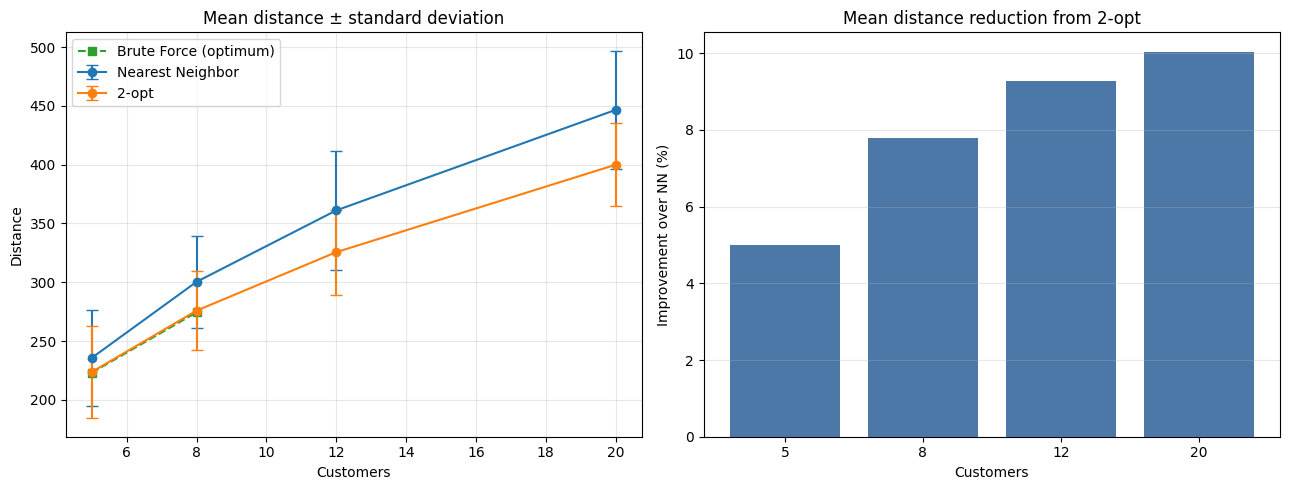

Figure saved to: /Users/marcoshoejer/Desktop/routeopt/results/robustness_benchmark.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].errorbar(
    summary['customers'], summary['nn_distance_mean'],
    yerr=summary['nn_distance_std'], marker='o', capsize=4,
    label='Nearest Neighbor',
)
axes[0].errorbar(
    summary['customers'], summary['two_opt_distance_mean'],
    yerr=summary['two_opt_distance_std'], marker='o', capsize=4,
    label='2-opt',
)
exact = summary[summary['customers'] <= 8]
axes[0].plot(
    exact['customers'], exact['exact_distance_mean'],
    marker='s', linestyle='--', label='Brute Force (optimum)',
)
axes[0].set(title='Mean distance ± standard deviation', xlabel='Customers', ylabel='Distance')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(summary['customers'].astype(str), summary['improvement_mean_pct'], color='#4c78a8')
axes[1].set(title='Mean distance reduction from 2-opt', xlabel='Customers', ylabel='Improvement over NN (%)')
axes[1].grid(axis='y', alpha=0.3)

fig.tight_layout()
figure_path = PROJECT_ROOT / 'results' / 'robustness_benchmark.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
plt.show()
print(f'Figure saved to: {figure_path}')

## Step 5 — Save the data to reproduce the analysis

The CSV stores one row per instance, the routes, and measurements for all three algorithms. These results are observations from this experiment, not a promise of universal performance.

In [6]:
csv_path = PROJECT_ROOT / 'results' / 'robustness_benchmark.csv'
csv_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(csv_path, index=False)
print(f'Results saved to: {csv_path}')

Results saved to: /Users/marcoshoejer/Desktop/routeopt/results/robustness_benchmark.csv


## Interpretation and Limitations

In this dataset, the mean improvement from 2-opt increased from 5.0% with 5 customers to 10.0% with 20; the heuristic improved 70%, 80%, 90%, and 100% of instances, respectively. This is evidence in favor of using 2-opt as a simple improvement to Nearest Neighbor for these instances.

However, this does not prove that the pattern will hold for other data: this experiment used only one synthetic uniform distribution, symmetric Euclidean distances, and a Nearest Neighbor starting route. 2-opt can end at a local optimum. Runtime depends on hardware and system load. The larger instances do not have a known exact solution in this experiment, so no optimality gap is reported for them.

## Conclusions and Next Phase

The experiment supports the conclusion that 2-opt can consistently improve Nearest Neighbor solutions, at the cost of additional runtime. Brute Force is useful as a reference for small instances, but its runtime already increases substantially at 8 customers.

Next: add Google OR-Tools as another method while keeping these instances, seeds, and metrics so the comparison remains fair. Afterward, road distances and operational constraints can be evaluated.